# ASR over trials — all runs on one plot

Collects `asr` from every `run_*/plots/plot_data/asr_over_trials.json` inside the given
experiment directory and plots them as points: X — trial index, Y — ASR.

Only `EXP_DIR` (and optionally `SPLIT`) needs to be edited in the cell below.

In [ ]:
# ── settings ─────────────────────────────────────────────────────────────────

# model directory containing run_1, run_2, ...
# paths are relative to this notebook (utils/)
EXP_DIR = "../logs_final/dynamic/harmbench_split/adaptive_with_guards/kimi_k3_"

SPLIT = "train"        # "train" | "val"
SHOW_MEAN = True       # draw the across-runs mean for each trial
TRIAL_START = 1        # renumber trials so the first one is 1 (None — keep as stored)

# font sizes
TICK_FONTSIZE = 18
LABEL_FONTSIZE = 22
TITLE_FONTSIZE = 24
LEGEND_FONTSIZE = 17
ANNOT_FONTSIZE = 14

# root for saved figures; the sub-path mirrors everything after the logs* directory
FIGURES_DIR = "../figures"
SAVE_FIGURES = True    # False — only show, do not write files
FIG_EXT = "pdf"        # "pdf"/"svg" — vector; "png" — raster
FIG_DPI = 200          # only affects raster formats

# the first trial used the same cipher in every run, so its ASR is averaged
# across runs and shown as a single point
AVERAGE_FIRST_TRIAL = True

# ─────────────────────────────────────────────────────────────────────────────
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

# keep text as editable/searchable text in the PDF (TrueType) instead of Type 3 outlines
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["svg.fonttype"] = "none"

# global font defaults, so anything not set explicitly is large too
plt.rcParams.update({
    "font.size": LABEL_FONTSIZE,
    "axes.titlesize": TITLE_FONTSIZE,
    "axes.labelsize": LABEL_FONTSIZE,
    "xtick.labelsize": TICK_FONTSIZE,
    "ytick.labelsize": TICK_FONTSIZE,
    "legend.fontsize": LEGEND_FONTSIZE,
})


def exp_rel_parts(exp_dir):
    """Path components of `exp_dir` that follow its logs* directory.

    .../logs_final/dynamic/harmbench_split/adaptive_with_guards/kimi_k3_
      -> ('dynamic', 'harmbench_split', 'adaptive_with_guards', 'kimi_k3_')
    """
    parts = [p for p in Path(exp_dir).parts if p not in ("/", "")]
    idx = [i for i, p in enumerate(parts) if p.startswith("logs")]
    if not idx:
        raise ValueError(f"No logs* directory in the experiment path: {exp_dir}")
    return parts[idx[-1] + 1:]


def figure_path(suffix, exp_dir=None, figures_dir=None, ext=None):
    """Destination for a figure: FIGURES_DIR/<path after logs*>/<last two dirs>_<suffix>.<ext>

    The directory is created if missing.
    """
    parts = exp_rel_parts(exp_dir or EXP_DIR)
    out_dir = Path(figures_dir or FIGURES_DIR).joinpath(*parts)
    out_dir.mkdir(parents=True, exist_ok=True)

    stem = "_".join(parts[-2:]) if len(parts) >= 2 else "".join(parts)
    name = f"{stem.rstrip('_')}_{suffix}"     # kimi_k3_ + val_asr -> kimi_k3_val_asr
    return out_dir / f"{name}.{ext or FIG_EXT}"


def save_fig(fig, suffix, ext=None, **kwargs):
    """Save `fig` under the mirrored figures path; returns the path (or None if disabled).

    Pass a list of extensions to write several formats at once, e.g. ext=["pdf", "png"].
    """
    if not SAVE_FIGURES:
        return None

    exts = [ext] if isinstance(ext, str) or ext is None else list(ext)
    paths = []
    for e in exts:
        path = figure_path(suffix, ext=e, **kwargs)
        fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
        print(f"[saved] {path}")
        paths.append(path)
    return paths[0] if len(paths) == 1 else paths

In [4]:
def load_runs(exp_dir, split="train", average_first_trial=None):
    """Read asr_over_trials.json from every run_* and return a long-format DataFrame."""
    exp_dir = Path(exp_dir)
    rows = []

    run_dirs = sorted(
        (p for p in exp_dir.glob("run_*") if p.is_dir()),
        key=lambda p: int(m.group(1)) if (m := re.search(r"(\d+)$", p.name)) else 0,
    )
    if not run_dirs:
        raise FileNotFoundError(f"No run_* directories found in {exp_dir}")

    for run_dir in run_dirs:
        f = run_dir / "plots" / "plot_data" / "asr_over_trials.json"
        if not f.exists():
            print(f"[skip] missing file: {f}")
            continue

        data = json.loads(f.read_text())
        if split not in data:
            print(f"[skip] no split '{split}' in {f} (available: {list(data)})")
            continue

        block = data[split]
        trials = block.get("trials") or list(range(len(block["asr"])))
        for trial, asr in zip(trials, block["asr"]):
            rows.append({"run": run_dir.name, "trial": trial, "asr": asr})

    if not rows:
        raise ValueError(f"Could not read any run from {exp_dir}")

    df = pd.DataFrame(rows)

    # the logs count trials from 0; renumber so the axis starts at TRIAL_START
    if TRIAL_START is not None:
        df["trial"] = df["trial"] - df["trial"].min() + TRIAL_START

    if average_first_trial is None:
        average_first_trial = AVERAGE_FIRST_TRIAL
    if average_first_trial:
        df = average_first_trial_asr(df)

    return df


def average_first_trial_asr(df):
    """The first trial shares one cipher across runs -> replace its ASR with the across-runs mean."""
    df = df.copy()
    mask = df["trial"] == df["trial"].min()
    df.loc[mask, "asr"] = df.loc[mask, "asr"].mean()
    return df


def first_trial_of(df):
    return df["trial"].min()


df = load_runs(EXP_DIR, SPLIT)
print(f"runs: {df['run'].nunique()}, points: {len(df)}")
if AVERAGE_FIRST_TRIAL:
    t0 = first_trial_of(df)
    print(f"trial {t0} averaged across runs: ASR = {df.loc[df['trial'] == t0, 'asr'].iloc[0]:.4f}")
df.head()

runs: 3, points: 60
trial 1 averaged across runs: ASR = 0.1600


,run,trial,asr
0,run_1,1,0.16
1,run_1,2,0.14
2,run_1,3,0.36
3,run_1,4,0.08
4,run_1,5,0.60


## Val: best-so-far

Validation split only. All points from all runs share one color; the step line connects
records only (running max over trials within each run).

In [5]:
from matplotlib.lines import Line2D

POINT_COLOR = "#9fb3c8"    # color of all points (same for every run)
STEP_COLOR = "#e07a5f"     # color of the best-so-far staircase
PER_RUN_STEPS = False      # False — one staircase over all runs pooled; True — one per run
ANNOTATE_RECORDS = True    # label each record with its trial index and ASR


def create_figure(exp_dir):

    def staircase(trials, values, x_end=None):
        """Monotone best-so-far staircase.

        Holds the current record flat until the first strictly higher point, jumps up there,
        and repeats; the last level is extended to `x_end`.
        Returns (xs, ys) for plotting and (rec_t, rec_v) — the record points themselves.
        """
        trials = np.asarray(trials)
        values = np.asarray(values, dtype=float)
        order = np.argsort(trials, kind="stable")
        trials, values = trials[order], values[order]

        best = np.maximum.accumulate(values)
        is_record = np.r_[True, best[1:] > best[:-1]]
        rec_t, rec_v = trials[is_record], best[is_record]

        xs, ys = [], []
        for i, (x, y) in enumerate(zip(rec_t, rec_v)):
            nxt = rec_t[i + 1] if i + 1 < len(rec_t) else x_end
            xs += [x]
            ys += [y]
            if nxt is not None and nxt > x:
                xs += [nxt, nxt]                       # flat to the next record, then jump up
                ys += [y, rec_v[i + 1] if i + 1 < len(rec_t) else y]
        return np.array(xs), np.array(ys), rec_t, rec_v


    dval = load_runs(exp_dir, "val").sort_values(["run", "trial"])
    t0_val = first_trial_of(dval)
    x_end = dval["trial"].max()

    # the first trial shares one cipher across runs -> one averaged point instead of N identical ones
    points = dval if not AVERAGE_FIRST_TRIAL else pd.concat([
        dval[dval["trial"] != t0_val],
        dval[dval["trial"] == t0_val].head(1),
    ])

    fig, ax = plt.subplots(figsize=(13, 6.5))

    # all points from all runs in one muted color
    ax.scatter(
        points["trial"], points["asr"],
        s=60, color=POINT_COLOR, alpha=0.55,
        edgecolors="none", zorder=2,
    )

    if PER_RUN_STEPS:
        series = [(run, sub["trial"], sub["asr"]) for run, sub in dval.groupby("run", sort=False)]
    else:
        pooled = dval.groupby("trial")["asr"].max().sort_index()   # best of all runs at each trial
        series = [("all runs", pooled.index, pooled.values)]

    for _, trials, values in series:
        xs, ys, rec_t, rec_v = staircase(trials, values, x_end=x_end)
        ax.plot(xs, ys, color=STEP_COLOR, linewidth=2.5, alpha=0.9,
                solid_capstyle="butt", zorder=3)
        ax.scatter(rec_t, rec_v, s=200, marker="*", color=STEP_COLOR,
                edgecolors="white", linewidths=0.9, zorder=4)

        if ANNOTATE_RECORDS:
            # trial index on the first line, the ASR reached there on the second
            for x, y in zip(rec_t, rec_v):
                ax.annotate(f"{y * 100:.0f}%", (x, y),
                            textcoords="offset points", xytext=(0, 14),
                            ha="center", va="bottom", linespacing=1.1,
                            fontsize=ANNOT_FONTSIZE, color="#555555")

    handles = [
        Line2D([], [], marker="o", linestyle="none", markersize=9,
            markerfacecolor=POINT_COLOR, markeredgecolor="none", label="ASR (all runs)"),
        Line2D([], [], color=STEP_COLOR, linewidth=2.5, marker="*", markersize=15,
            markerfacecolor=STEP_COLOR, markeredgecolor="white",
            label="best-so-far" + (" (per run)" if PER_RUN_STEPS else "")),
    ]

    ax.set_xlabel("Trials", fontsize=LABEL_FONTSIZE)
    ax.set_ylabel("ASR (%)", fontsize=LABEL_FONTSIZE)
    ax.set_xticks(sorted(dval["trial"].unique()))
    ax.set_ylim(-0.02, 1.14)   # headroom for the two-line labels above high records
    ax.set_xlim(dval["trial"].min() - 0.5, dval["trial"].max() + 0.5)

    # ASR is stored as a fraction (0..1) -> show the axis as percent
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

    ax.tick_params(axis="both", which="major", labelsize=TICK_FONTSIZE)
    ax.grid(axis="y", color="#ececec", linewidth=0.8, zorder=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(handles=handles, frameon=True, fontsize=LEGEND_FONTSIZE, loc="upper left", ncol=2)

    fig.tight_layout()
    save_fig(fig, "val_asr", exp_dir=exp_dir)
    plt.show()


In [ ]:
exp_dirs = ["../logs_final/dynamic/harmbench_split/adaptive_no_guards/gemini_3_5_flash_", "../logs_final/dynamic/harmbench_split/adaptive_no_guards/kimi_k3_", "../logs_final/dynamic/harmbench_split/adaptive_no_guards/llama_4_maverick_", "../logs_final/dynamic/harmbench_split/adaptive_no_guards/qwen3_5_397b_a17b_", "../logs_final/dynamic/harmbench_split/adaptive_with_guards/gemini_3_5_flash_", "../logs_final/dynamic/harmbench_split/adaptive_with_guards/kimi_k3_", "../logs_final/dynamic/harmbench_split/adaptive_with_guards/llama_4_maverick_", "../logs_final/dynamic/harmbench_split/adaptive_with_guards/qwen3_5_397b_a17b_"]

Creating figure for autojailbreak/logs_final/dynamic/harmbench_split/adaptive_no_guards/gemini_3_5_flash_ ...
[saved] autojailbreak/figures/dynamic/harmbench_split/adaptive_no_guards/gemini_3_5_flash_/adaptive_no_guards_gemini_3_5_flash_val_asr.pdf


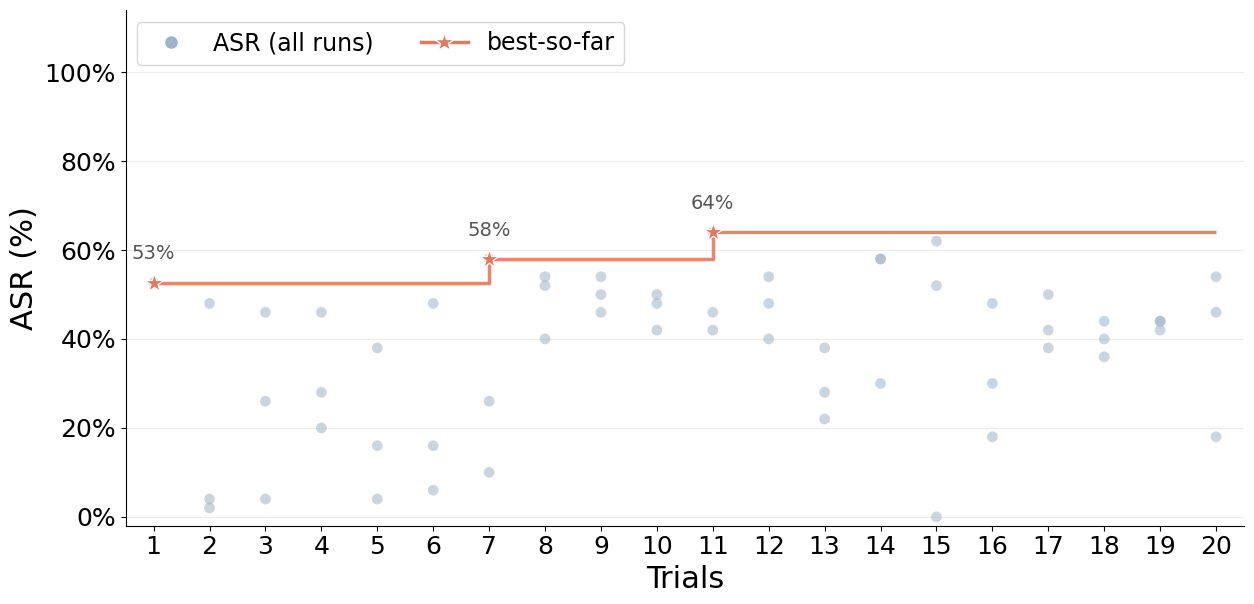

Creating figure for autojailbreak/logs_final/dynamic/harmbench_split/adaptive_no_guards/kimi_k3_ ...
[saved] autojailbreak/figures/dynamic/harmbench_split/adaptive_no_guards/kimi_k3_/adaptive_no_guards_kimi_k3_val_asr.pdf


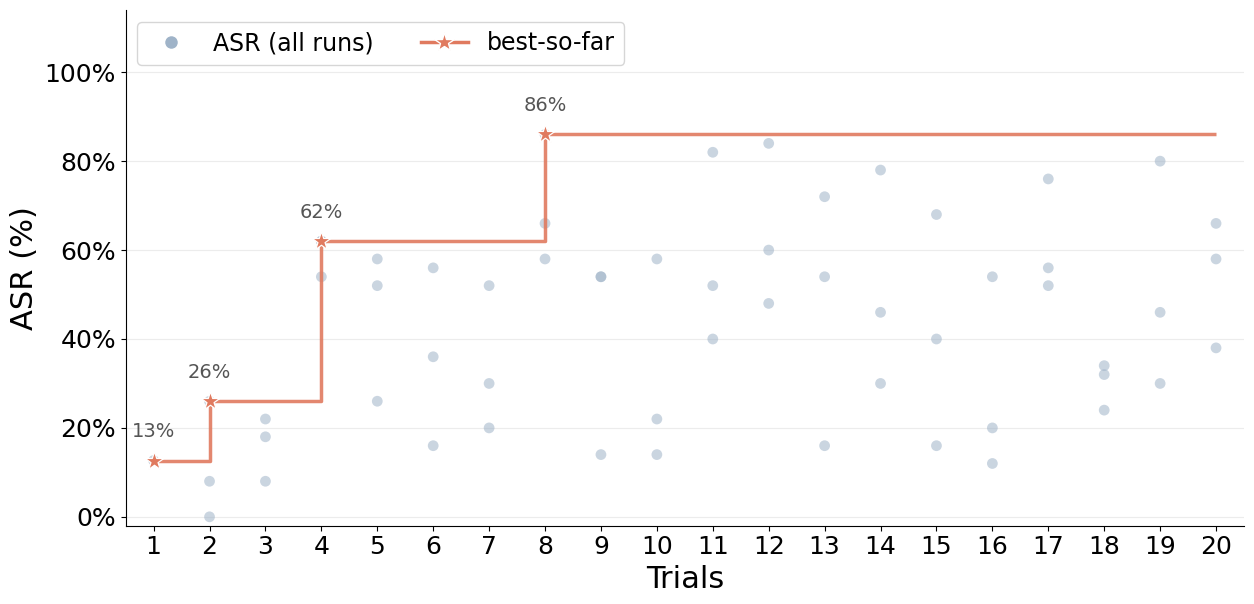

Creating figure for autojailbreak/logs_final/dynamic/harmbench_split/adaptive_no_guards/llama_4_maverick_ ...
[saved] autojailbreak/figures/dynamic/harmbench_split/adaptive_no_guards/llama_4_maverick_/adaptive_no_guards_llama_4_maverick_val_asr.pdf


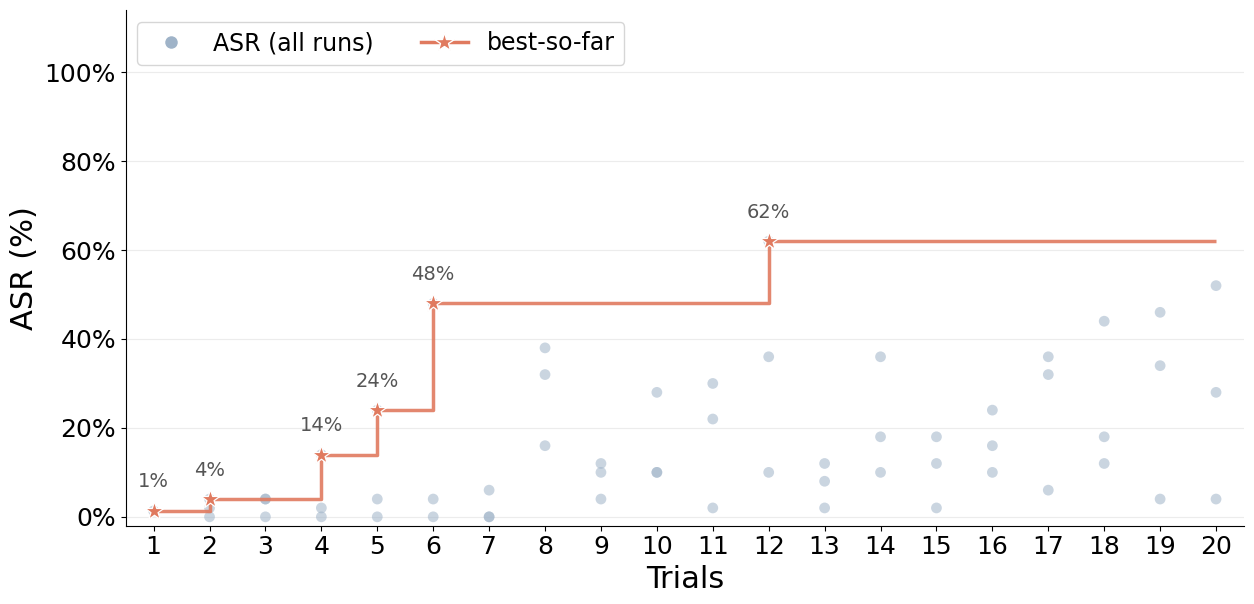

Creating figure for autojailbreak/logs_final/dynamic/harmbench_split/adaptive_no_guards/qwen3_5_397b_a17b_ ...
[saved] autojailbreak/figures/dynamic/harmbench_split/adaptive_no_guards/qwen3_5_397b_a17b_/adaptive_no_guards_qwen3_5_397b_a17b_val_asr.pdf


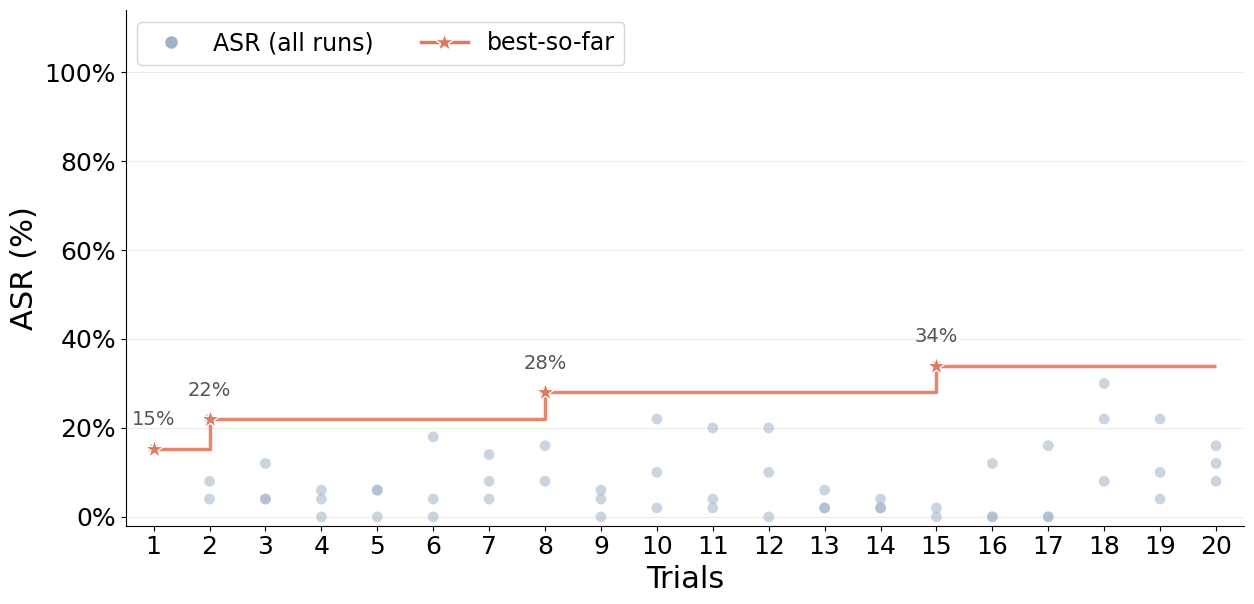

Creating figure for autojailbreak/logs_final/dynamic/harmbench_split/adaptive_with_guards/gemini_3_5_flash_ ...
[saved] autojailbreak/figures/dynamic/harmbench_split/adaptive_with_guards/gemini_3_5_flash_/adaptive_with_guards_gemini_3_5_flash_val_asr.pdf


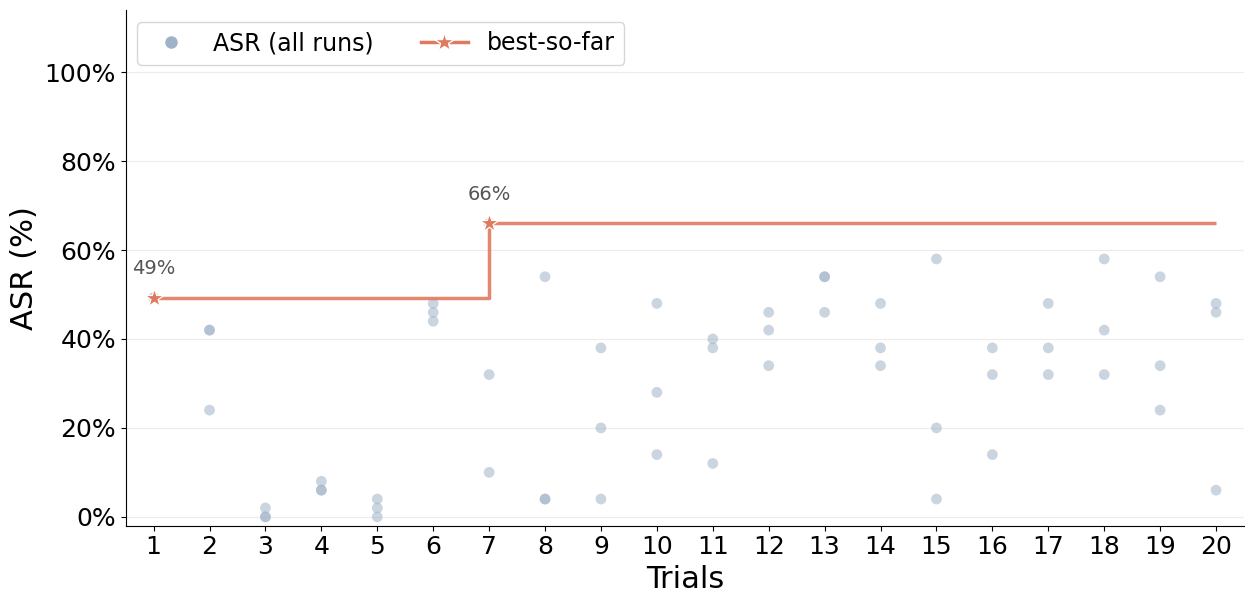

Creating figure for autojailbreak/logs_final/dynamic/harmbench_split/adaptive_with_guards/kimi_k3_ ...
[saved] autojailbreak/figures/dynamic/harmbench_split/adaptive_with_guards/kimi_k3_/adaptive_with_guards_kimi_k3_val_asr.pdf


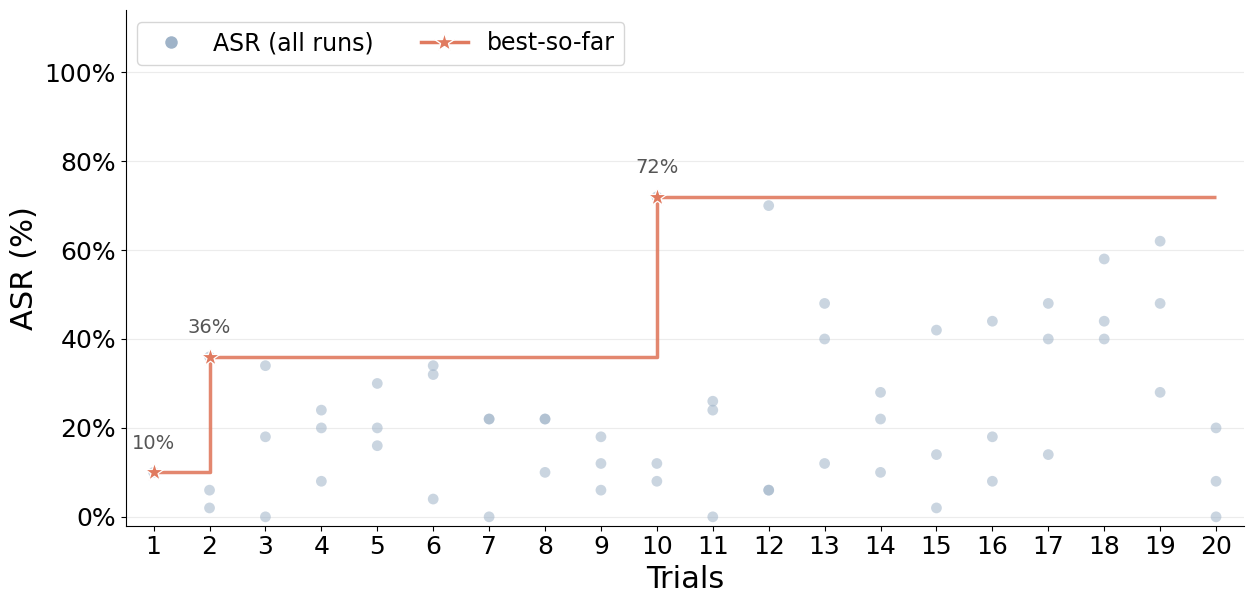

Creating figure for autojailbreak/logs_final/dynamic/harmbench_split/adaptive_with_guards/llama_4_maverick_ ...
[saved] autojailbreak/figures/dynamic/harmbench_split/adaptive_with_guards/llama_4_maverick_/adaptive_with_guards_llama_4_maverick_val_asr.pdf


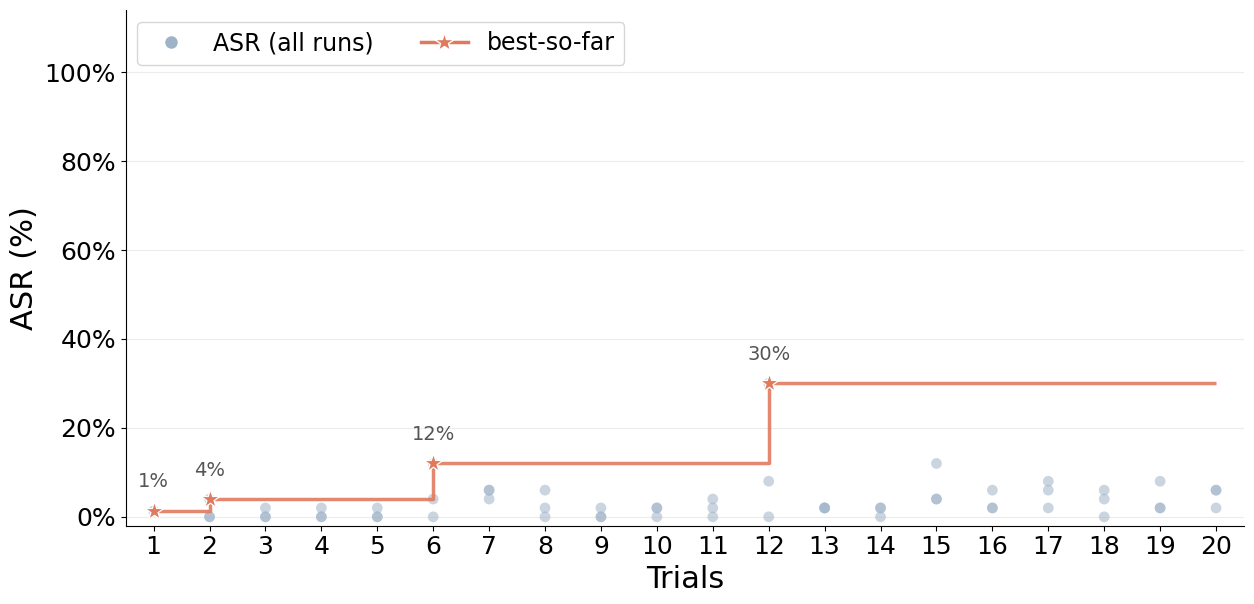

Creating figure for autojailbreak/logs_final/dynamic/harmbench_split/adaptive_with_guards/qwen3_5_397b_a17b_ ...
[saved] autojailbreak/figures/dynamic/harmbench_split/adaptive_with_guards/qwen3_5_397b_a17b_/adaptive_with_guards_qwen3_5_397b_a17b_val_asr.pdf


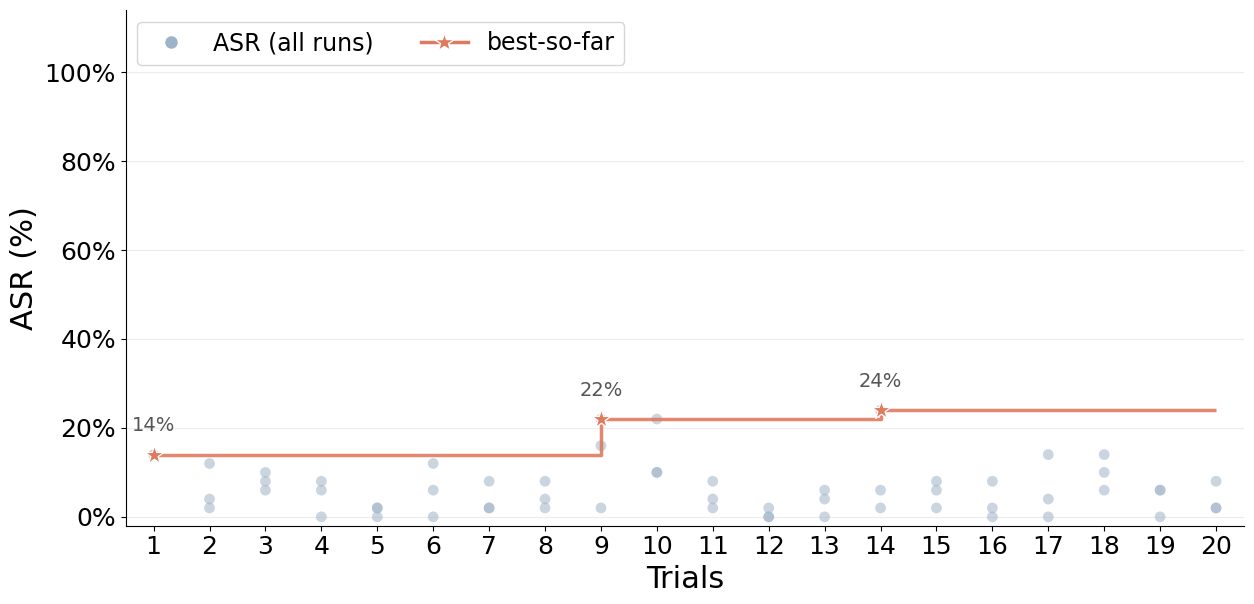

In [7]:
for exp_dir in exp_dirs:
    print(f"Creating figure for {exp_dir} ...")
    create_figure(exp_dir)